In [19]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv('mpg.csv')
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    392 non-null    float64
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model_year    398 non-null    int64  
 7   origin        398 non-null    str    
 8   name          398 non-null    str    
dtypes: float64(4), int64(3), str(2)
memory usage: 28.1 KB


In [5]:
df.head(1)

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu


In [ ]:
df = df.drop(columns=['name','origin'])
df['horsepower']= df['horsepower'].fillna(df['horsepower'].median())
print(df.shape, "|", df.isna().sum().sum(), "missing") # df.isna().sum().sum() means total missing values in the DataFrame, .sum() written twice as it first sums the missing values for each column, and then sums those results to get the total.
df.head()

(398, 7) | 0 missing


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year
0,18.0,8,307.0,130.0,3504,12.0,70
1,15.0,8,350.0,165.0,3693,11.5,70
2,18.0,8,318.0,150.0,3436,11.0,70
3,16.0,8,304.0,150.0,3433,12.0,70
4,17.0,8,302.0,140.0,3449,10.5,70


In [7]:
X = df.drop(columns='mpg')
y = df['mpg']
print(X.shape, y.shape)

(398, 6) (398,)


In [8]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size= 0.2, random_state= 42
)
print(X_train.shape, X_test.shape)

(318, 6) (80, 6)


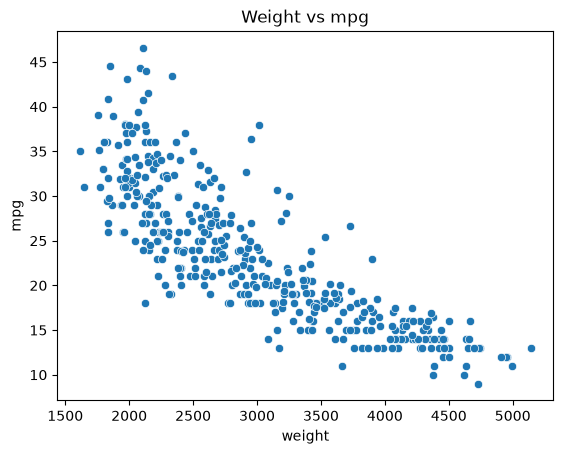

In [9]:
sns.scatterplot(data = df, x = 'weight', y = 'mpg')
plt.title("Weight vs mpg")
plt.show()

y = mx + c, with new names:

mpg = coef × weight + intercept

Many lines can be drawn. Only one fits best.

Residual = actual − predicted. The vertical distance from a point to the line.

The best line has the smallest total of squared residuals. Squaring stops +4 and −4 cancelling into 0.

With many features the line cannot be drawn any more, but the job is the same:

mpg = w1×weight + w2×horsepower + ... + intercept


Q1. A model predicts 22 for a car whose actual mileage is 26. What is the residual?

Q2. One residual is +4 and another is −4. If we just added them, what would the total be, and why is that a problem?

Answers

1. 26 − 22 = 4.

2. Zero. A model that is wrong twice looks perfect. Squaring makes both count as 16. Hence, for RMSE we square the errors so that large scale errors are penalised.

In [12]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(X_train[['weight']],y_train)
print("coefficient:", model.coef_)
print("intercept:   ",model.intercept_)

coefficient: [-0.00780524]
intercept:    46.78206336645047


mpg = -0.0078 × weight + 46.78

The coefficient is negative, so weight and mpg have an inverse relationship — heavier car, lower mileage.

In [ ]:
print(model.score(X_test[['weight']],y_test)) # R2 score

0.722971057303075


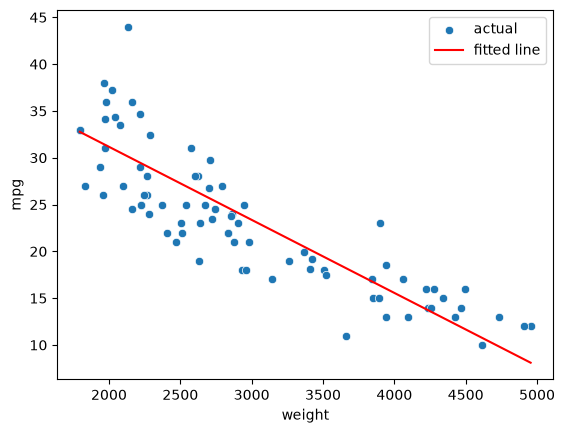

In [14]:
sns.scatterplot( x = X_test['weight'], y= y_test, label = 'actual')
sns.lineplot(x = X_test['weight'], y = model.predict(X_test[['weight']]), color= 'red', label = 'fitted line')
plt.show()

In [15]:
model_all = LinearRegression()
model_all.fit(X_train, y_train)
print(model_all.score(X_test, y_test))

0.8244245330943358


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
y_pred = model_all.predict(X_test)
print("MAE: ", mean_absolute_error(y_test, y_pred)) # Mean absolute error
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred))) # Root mean squared error
print("R2:  ", r2_score(y_test, y_pred)) # R2 score

MAE:  2.466780800452033
RMSE: 3.0724694408998414
R2:   0.8244245330943358


REMEMBER: RMSE is always greater than or equal to MAE.

Q1. A house price model reports MAE = 2.5 lakh. What does that mean in one line?

Q2. Model A has R² = 0.91, model B has R² = 0.40. Which is better, and what does R² = 0 mean?

Answers

1. On average the predicted price is off by 2.5 lakh.

2. A. R² = 0 means no better than always guessing the average price.

## Does scaling help regression?

In [24]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.fit_transform(X_test)
print(X_train_scaled.shape, X_test_scaled.shape)

(318, 6) (80, 6)


In [ ]:
model_scaled = LinearRegression()
model_scaled.fit(X_train_scaled, y_train)
print("Without scaling:", model_all.score(X_test, y_test))
print("With scaling:", model_scaled.score(X_test_scaled, y_test)) # not much difference in r2 score after scaling

Without scaling: 0.8244245330943358
With scaling: 0.831170702016536


In [ ]:
pd.DataFrame({
    'feature': X_train.columns,
    'coef without scaling': model_all.coef_.round(3),
    'coef with scaling': model_scaled.coef_.round(3) # significant difference in coefficient after scaling
})

,feature,coef without scaling,coef with scaling
0,cylinders,0.069,0.116
1,displacement,0.002,0.165
2,horsepower,0.003,0.107
3,weight,-0.007,-5.912
4,acceleration,0.081,0.222
5,model_year,0.801,2.883


In [27]:
from sklearn.neighbors import KNeighborsRegressor
knn = KNeighborsRegressor()
knn.fit(X_train, y_train)
acc_knn_raw = knn.score(X_test, y_test)
print(acc_knn_raw)

0.7659996807953288


In [28]:
knn_scaled = KNeighborsRegressor()
knn_scaled.fit(X_train_scaled, y_train)
acc_kk_scaled = knn_scaled.score(X_test_scaled, y_test)
print(acc_kk_scaled)

0.8569216324633708


In [ ]:
pd.DataFrame({
    'model': ['LinearRegression', 'KNN Regressor (no scaling)', 'KNN Regressor (scaled)'],
    'R2 score': [round(model_all.score(X_test, y_test),4),round(acc_knn_raw, 4),round(acc_kk_scaled, 4)]
})

,model,R2
0,LinearRegression,0.8244
1,KNN Regressor (no scaling),0.7660
2,KNN Regressor (scaled),0.8569
